# Infosys Financial Analysis — Python & SQL

**Purpose:** Reproducible data-analysis layer for the Infosys equity-research and valuation workbook.

- Historical basis: consolidated Ind AS, FY2021–FY2026.
- Units: INR crore except EPS, ratios and multiples.
- Input: `workbook/Infosys_Final.xlsx` in this repository.
- Output: `database/Infosys_Analysis.db` plus notebook analysis and charts.

> This notebook does not invent missing values. Blank source values remain null. `CFO less capex` is an analyst proxy, not reported free cash flow. This is an educational analysis, not an independent audit.


## 1. Set up and load the workbook

**What we do:** Import the required Python libraries and read the historical and ratio sheets.

**Why:** The workbook remains the controlled source of historical data. Python is used to reshape, validate, analyse and visualize it without manually retyping values.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Resolve paths for this GitHub repository layout, while retaining a fallback
# for users who keep the workbook beside the notebook.
HERE = Path.cwd().resolve()
if HERE.name == 'notebooks':
    PROJECT_ROOT = HERE.parent
else:
    PROJECT_ROOT = HERE

WORKBOOK = PROJECT_ROOT / 'workbook' / 'Infosys_Final.xlsx'
if not WORKBOOK.exists():
    WORKBOOK = HERE / 'Infosys_Final.xlsx'
if not WORKBOOK.exists():
    raise FileNotFoundError(
        'Could not find Infosys_Final.xlsx. Open Jupyter from the repository root '
        'or place the workbook in the current notebook folder.'
    )

xls = pd.ExcelFile(WORKBOOK)
assert 'Normalized History' in xls.sheet_names
assert 'Historical Ratios' in xls.sheet_names

raw = pd.read_excel(WORKBOOK, sheet_name='Normalized History', header=None)
ratio_raw = pd.read_excel(WORKBOOK, sheet_name='Historical Ratios', header=None)
print(f'Workbook loaded: {WORKBOOK.resolve()}')
print(f'Worksheets available: {len(xls.sheet_names)}')


Workbook loaded: /mnt/data/Infosys_Final.xlsx
Worksheets available: 45


## 2. Reshape the six-year financial history

**What we do:** Convert the wide historical schedule into a tidy table with one row per metric and fiscal year.

**Why:** Long-format data is easier to filter, aggregate, query in SQL and reuse in visualizations. We preserve source mapping, unit and accounting basis.

In [2]:
years = ["FY2021", "FY2022", "FY2023", "FY2024", "FY2025", "FY2026"]
header_row = 5
metric_rows = raw.iloc[6:39].copy()
metric_rows = metric_rows[metric_rows.iloc[:, 1].notna()]

records = []
for _, row in metric_rows.iterrows():
    statement, metric, source_mapping, unit = row.iloc[0], row.iloc[1], row.iloc[2], row.iloc[3]
    for idx, year in enumerate(years, start=4):
        value = row.iloc[idx]
        records.append({
            "fiscal_year": year,
            "fiscal_year_end": int(year[-4:]),
            "statement": statement,
            "metric": metric,
            "source_mapping": source_mapping,
            "unit": unit,
            "value": pd.to_numeric(value, errors="coerce"),
            "accounting_basis": "Consolidated Ind AS"
        })

financials = pd.DataFrame(records)
financials["value"] = pd.to_numeric(financials["value"], errors="coerce")
print("Rows:", len(financials), "| populated values:", int(financials["value"].notna().sum()))
display(financials.head(12))

Rows: 198 | populated values: 186


,fiscal_year,fiscal_year_end,statement,metric,source_mapping,unit,value,accounting_basis
0,FY2021,2021,INCOME STATEMENT,Revenue,Revenue from operations / Revenue,INR crore,100472.0,Consolidated Ind AS
1,FY2022,2022,INCOME STATEMENT,Revenue,Revenue from operations / Revenue,INR crore,121641.0,Consolidated Ind AS
2,FY2023,2023,INCOME STATEMENT,Revenue,Revenue from operations / Revenue,INR crore,146767.0,Consolidated Ind AS
3,FY2024,2024,INCOME STATEMENT,Revenue,Revenue from operations / Revenue,INR crore,153670.0,Consolidated Ind AS
4,FY2025,2025,INCOME STATEMENT,Revenue,Revenue from operations / Revenue,INR crore,162990.0,Consolidated Ind AS
5,FY2026,2026,INCOME STATEMENT,Revenue,Revenue from operations / Revenue,INR crore,178650.0,Consolidated Ind AS
6,FY2021,2021,INCOME STATEMENT,Other income,"Other income, net / Other income",INR crore,2201.0,Consolidated Ind AS
7,FY2022,2022,INCOME STATEMENT,Other income,"Other income, net / Other income",INR crore,2295.0,Consolidated Ind AS
8,FY2023,2023,INCOME STATEMENT,Other income,"Other income, net / Other income",INR crore,2701.0,Consolidated Ind AS
9,FY2024,2024,INCOME STATEMENT,Other income,"Other income, net / Other income",INR crore,4711.0,Consolidated Ind AS


## 3. Import historical ratios

**What we do:** Reshape the ratio schedule into a second tidy table.

**Why:** Keeping financial statement data and derived ratios separate makes it clear which values are reported inputs and which are calculated indicators.

In [3]:
ratio_header = 6
ratio_rows = ratio_raw.iloc[7:21].copy()
ratio_rows = ratio_rows[ratio_rows.iloc[:, 0].notna()]
ratio_records = []
for _, row in ratio_rows.iterrows():
    metric, definition, unit = row.iloc[0], row.iloc[1], row.iloc[2]
    for idx, year in enumerate(years, start=3):
        ratio_records.append({
            "fiscal_year": year,
            "fiscal_year_end": int(year[-4:]),
            "metric": metric,
            "definition": definition,
            "unit": unit,
            "value": pd.to_numeric(row.iloc[idx], errors="coerce"),
            "accounting_basis": "Consolidated Ind AS"
        })
ratios = pd.DataFrame(ratio_records)
print("Ratio rows:", len(ratios), "| populated values:", int(ratios["value"].notna().sum()))
display(ratios.head(10))

Ratio rows: 84 | populated values: 78


,fiscal_year,fiscal_year_end,metric,definition,unit,value,accounting_basis
0,FY2021,2021,Revenue growth,Current-year revenue / prior-year revenue − 1,%,NaN,Consolidated Ind AS
1,FY2022,2022,Revenue growth,Current-year revenue / prior-year revenue − 1,%,0.210696,Consolidated Ind AS
2,FY2023,2023,Revenue growth,Current-year revenue / prior-year revenue − 1,%,0.206559,Consolidated Ind AS
3,FY2024,2024,Revenue growth,Current-year revenue / prior-year revenue − 1,%,0.047034,Consolidated Ind AS
4,FY2025,2025,Revenue growth,Current-year revenue / prior-year revenue − 1,%,0.060649,Consolidated Ind AS
5,FY2026,2026,Revenue growth,Current-year revenue / prior-year revenue − 1,%,0.096080,Consolidated Ind AS
6,FY2021,2021,PBT margin,Profit before tax / revenue,%,0.265029,Consolidated Ind AS
7,FY2022,2022,PBT margin,Profit before tax / revenue,%,0.247532,Consolidated Ind AS
8,FY2023,2023,PBT margin,Profit before tax / revenue,%,0.227040,Consolidated Ind AS
9,FY2024,2024,PBT margin,Profit before tax / revenue,%,0.234190,Consolidated Ind AS


## 4. Data quality and reconciliation checks

**What we do:** Test revenue presence, uniqueness, key financial identities and proxy calculations.

**Why:** Analysis should not proceed without basic integrity checks. These checks are intentionally described as analytical validations, not a complete independent audit.

In [4]:
def get_metric(metric, year):
    hit = financials.loc[
        (financials["metric"] == metric) & (financials["fiscal_year"] == year), "value"
    ]
    return np.nan if hit.empty else hit.iloc[0]

checks = []
def add_check(check_name, year, passed, detail):
    checks.append({"check_name": check_name, "fiscal_year": year,
                   "status": "PASS" if bool(passed) else "REVIEW", "detail": detail})

# One row per metric-year
dupes = financials.duplicated(["metric", "fiscal_year"]).sum()
add_check("Unique metric-year keys", "FY2021-FY2026", dupes == 0, f"Duplicate keys: {dupes}")

for year in years:
    revenue = get_metric("Revenue", year)
    pbt = get_metric("Profit before tax", year)
    pat = get_metric("Profit after tax", year)
    tax = get_metric("Tax expense", year)
    cfo = get_metric("Cash flow from operating activities", year)
    capex = get_metric("Capital expenditure", year)
    proxy = get_metric("CFO less capex proxy", year)
    assets = get_metric("Total assets", year)
    equity = get_metric("Total equity", year)
    current_assets = get_metric("Total current assets", year)
    current_liabilities = get_metric("Total current liabilities", year)

    add_check("Revenue populated and positive", year,
              pd.notna(revenue) and revenue > 0, f"Revenue={revenue}")
    add_check("PBT + tax = PAT (rounded tolerance)", year,
              pd.notna(pbt) and pd.notna(tax) and pd.notna(pat) and abs((pbt-tax)-pat) <= 1,
              f"PBT {pbt} - tax {tax} vs PAT {pat}")
    add_check("CFO less capex proxy arithmetic", year,
              pd.notna(cfo) and pd.notna(capex) and pd.notna(proxy) and abs((cfo-capex)-proxy) <= 1,
              f"CFO {cfo} - capex {capex} vs proxy {proxy}")
    add_check("Assets exceed or equal equity", year,
              pd.notna(assets) and pd.notna(equity) and assets >= equity,
              f"Assets={assets}; equity={equity}")
    add_check("Current ratio inputs positive", year,
              pd.notna(current_assets) and pd.notna(current_liabilities)
              and current_assets > 0 and current_liabilities > 0,
              f"Current assets={current_assets}; current liabilities={current_liabilities}")

quality = pd.DataFrame(checks)
display(quality)
print(quality["status"].value_counts().to_dict())

,check_name,fiscal_year,status,detail
0,Unique metric-year keys,FY2021-FY2026,PASS,Duplicate keys: 0
1,Revenue populated and positive,FY2021,PASS,Revenue=100472.0
2,PBT + tax = PAT (rounded tolerance),FY2021,PASS,PBT 26628.0 - tax 7205.0 vs PAT 19423.0
3,CFO less capex proxy arithmetic,FY2021,PASS,CFO 23224.0 - capex 2107.0 vs proxy 21117.0
4,Assets exceed or equal equity,FY2021,PASS,Assets=108386.0; equity=76782.0
5,Current ratio inputs positive,FY2021,PASS,Current assets=60733.0; current liabilities=23...
6,Revenue populated and positive,FY2022,PASS,Revenue=121641.0
7,PBT + tax = PAT (rounded tolerance),FY2022,PASS,PBT 30110.0 - tax 7964.0 vs PAT 22146.0
8,CFO less capex proxy arithmetic,FY2022,PASS,CFO 23885.0 - capex 2161.0 vs proxy 21724.0
9,Assets exceed or equal equity,FY2022,PASS,Assets=117885.0; equity=75736.0


{'PASS': 31}


## 5. Financial trend analysis

**What we do:** Calculate revenue growth, PBT/PAT margins, CFO margin and the CFO-less-capex proxy margin from the underlying statement rows.

**Why:** Recalculating selected indicators in Python independently of the prebuilt ratio sheet is a useful cross-check and creates a reproducible analysis trail.

In [5]:
wide = financials.pivot(index="metric", columns="fiscal_year", values="value")
trend = pd.DataFrame(index=years)
trend.index.name = "fiscal_year"
trend["revenue_inr_cr"] = [get_metric("Revenue", y) for y in years]
trend["pbt_inr_cr"] = [get_metric("Profit before tax", y) for y in years]
trend["pat_inr_cr"] = [get_metric("Profit after tax", y) for y in years]
trend["cfo_inr_cr"] = [get_metric("Cash flow from operating activities", y) for y in years]
trend["capex_inr_cr"] = [get_metric("Capital expenditure", y) for y in years]
trend["cfo_less_capex_proxy_inr_cr"] = trend["cfo_inr_cr"] - trend["capex_inr_cr"]
trend["revenue_growth_pct"] = trend["revenue_inr_cr"].pct_change() * 100
trend["pbt_margin_pct"] = trend["pbt_inr_cr"] / trend["revenue_inr_cr"] * 100
trend["pat_margin_pct"] = trend["pat_inr_cr"] / trend["revenue_inr_cr"] * 100
trend["cfo_margin_pct"] = trend["cfo_inr_cr"] / trend["revenue_inr_cr"] * 100
trend["cfo_less_capex_proxy_margin_pct"] = trend["cfo_less_capex_proxy_inr_cr"] / trend["revenue_inr_cr"] * 100
display(trend.round(2))

,revenue_inr_cr,pbt_inr_cr,pat_inr_cr,cfo_inr_cr,capex_inr_cr,cfo_less_capex_proxy_inr_cr,revenue_growth_pct,pbt_margin_pct,pat_margin_pct,cfo_margin_pct,cfo_less_capex_proxy_margin_pct
fiscal_year,,,,,,,,,,,
FY2021,100472.0,26628.0,19423.0,23224.0,2107.0,21117.0,NaN,26.50,19.33,23.11,21.02
FY2022,121641.0,30110.0,22146.0,23885.0,2161.0,21724.0,21.07,24.75,18.21,19.64,17.86
FY2023,146767.0,33322.0,24108.0,22467.0,2579.0,19888.0,20.66,22.70,16.43,15.31,13.55
FY2024,153670.0,35988.0,26248.0,25210.0,2201.0,23009.0,4.70,23.42,17.08,16.41,14.97
FY2025,162990.0,37608.0,26750.0,35694.0,2237.0,33457.0,6.06,23.07,16.41,21.90,20.53
FY2026,178650.0,39995.0,29474.0,33986.0,2727.0,31259.0,9.61,22.39,16.50,19.02,17.50


## 6. Visual analysis

**What we do:** Plot revenue and profit trends, operating cash-flow conversion and margins.

**Why:** Visuals help communicate direction, volatility and relationships more quickly than a table alone. They are descriptive, not causal explanations.

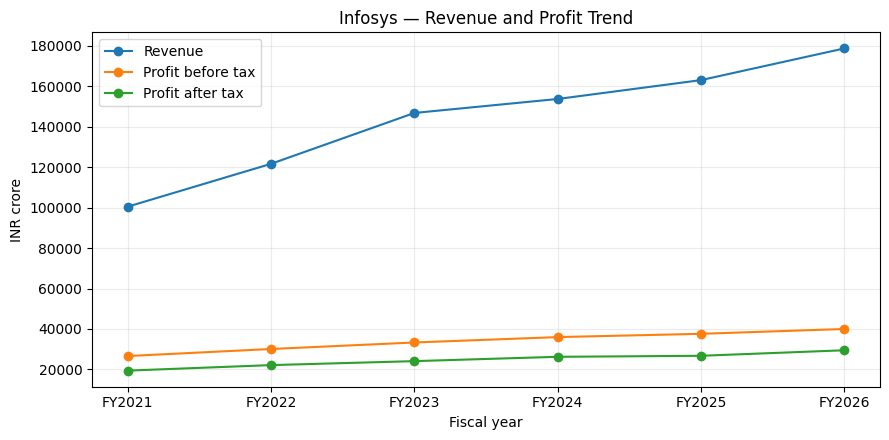

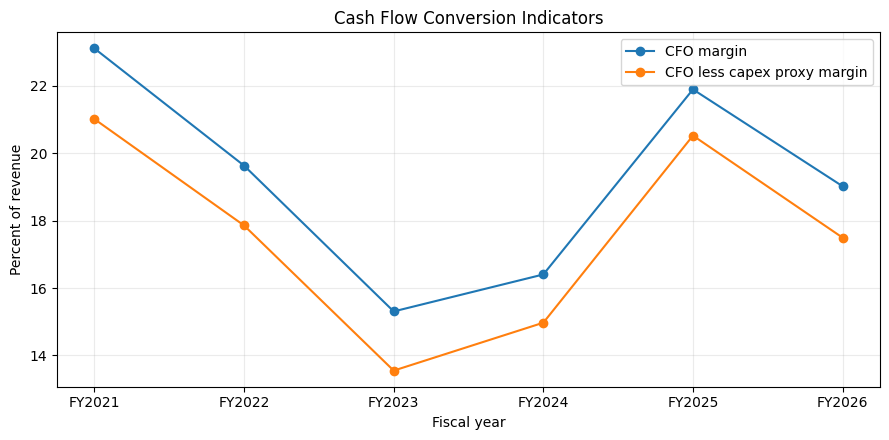

In [6]:
plt.figure(figsize=(9, 4.5))
plt.plot(trend.index, trend["revenue_inr_cr"], marker="o", label="Revenue")
plt.plot(trend.index, trend["pbt_inr_cr"], marker="o", label="Profit before tax")
plt.plot(trend.index, trend["pat_inr_cr"], marker="o", label="Profit after tax")
plt.title("Infosys — Revenue and Profit Trend")
plt.ylabel("INR crore")
plt.xlabel("Fiscal year")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
plt.plot(trend.index, trend["cfo_margin_pct"], marker="o", label="CFO margin")
plt.plot(trend.index, trend["cfo_less_capex_proxy_margin_pct"], marker="o",
         label="CFO less capex proxy margin")
plt.title("Cash Flow Conversion Indicators")
plt.ylabel("Percent of revenue")
plt.xlabel("Fiscal year")
plt.grid(True, alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

## 7. Load the analysis tables into SQLite

**What we do:** Create a local SQLite database containing financials, ratios, trend outputs, quality checks and the source register.

**Why:** This makes the same source data queryable using SQL and demonstrates a practical Python-to-SQL workflow. The database is rebuilt from the workbook so it can be refreshed.

In [7]:
# Store the reproducible SQLite database in the repository database/ folder.
DB_DIR = PROJECT_ROOT / 'database'
DB_DIR.mkdir(parents=True, exist_ok=True)
DB_PATH = DB_DIR / 'Infosys_Analysis.db'
source_register = pd.read_excel(WORKBOOK, sheet_name='Source Register')

with sqlite3.connect(DB_PATH) as conn:
    financials.to_sql('annual_financials', conn, if_exists='replace', index=False)
    ratios.to_sql('annual_ratios', conn, if_exists='replace', index=False)
    trend.reset_index().to_sql('annual_trend', conn, if_exists='replace', index=False)
    quality.to_sql('quality_checks', conn, if_exists='replace', index=False)
    source_register.to_sql('source_register', conn, if_exists='replace', index=False)

print('SQLite database created:', DB_PATH.resolve())
with sqlite3.connect(DB_PATH) as conn:
    table_counts = pd.read_sql_query(
        "SELECT name AS table_name FROM sqlite_master WHERE type='table' ORDER BY name", conn
    )
display(table_counts)


SQLite database created: /mnt/data/Infosys_Analysis.db


,table_name
0,annual_financials
1,annual_ratios
2,annual_trend
3,quality_checks
4,source_register


## 8. Run SQL analysis from Python

**What we do:** Execute SQL queries against the SQLite database and display results.

**Why:** This validates that the database is useful beyond being a static file and demonstrates joins, grouping, conditional aggregation and data-quality querying.

In [8]:
sql_queries = {
    "Revenue and profit trend": """
        SELECT fiscal_year,
               MAX(CASE WHEN metric='Revenue' THEN value END) AS revenue_inr_cr,
               MAX(CASE WHEN metric='Profit before tax' THEN value END) AS pbt_inr_cr,
               MAX(CASE WHEN metric='Profit after tax' THEN value END) AS pat_inr_cr
        FROM annual_financials
        GROUP BY fiscal_year, fiscal_year_end
        ORDER BY fiscal_year_end;
    """,
    "Profitability margins": """
        SELECT fiscal_year,
               ROUND(100.0 * MAX(CASE WHEN metric='Profit before tax' THEN value END) /
                     MAX(CASE WHEN metric='Revenue' THEN value END), 2) AS pbt_margin_pct,
               ROUND(100.0 * MAX(CASE WHEN metric='Profit after tax' THEN value END) /
                     MAX(CASE WHEN metric='Revenue' THEN value END), 2) AS pat_margin_pct
        FROM annual_financials
        GROUP BY fiscal_year, fiscal_year_end
        ORDER BY fiscal_year_end;
    """,
    "Cash-flow proxy": """
        SELECT fiscal_year,
               MAX(CASE WHEN metric='Cash flow from operating activities' THEN value END) AS cfo,
               MAX(CASE WHEN metric='Capital expenditure' THEN value END) AS capex,
               MAX(CASE WHEN metric='CFO less capex proxy' THEN value END) AS workbook_proxy,
               MAX(CASE WHEN metric='Cash flow from operating activities' THEN value END)
                 - MAX(CASE WHEN metric='Capital expenditure' THEN value END) AS recalculated_proxy
        FROM annual_financials
        GROUP BY fiscal_year, fiscal_year_end
        ORDER BY fiscal_year_end;
    """,
    "Quality review items": """
        SELECT check_name, fiscal_year, status, detail
        FROM quality_checks
        WHERE status <> 'PASS'
        ORDER BY fiscal_year, check_name;
    """
}
with sqlite3.connect(DB_PATH) as conn:
    for title, query in sql_queries.items():
        print("\\n", title)
        display(pd.read_sql_query(query, conn))

\n Revenue and profit trend


,fiscal_year,revenue_inr_cr,pbt_inr_cr,pat_inr_cr
0,FY2021,100472.0,26628.0,19423.0
1,FY2022,121641.0,30110.0,22146.0
2,FY2023,146767.0,33322.0,24108.0
3,FY2024,153670.0,35988.0,26248.0
4,FY2025,162990.0,37608.0,26750.0
5,FY2026,178650.0,39995.0,29474.0


\n Profitability margins


,fiscal_year,pbt_margin_pct,pat_margin_pct
0,FY2021,26.50,19.33
1,FY2022,24.75,18.21
2,FY2023,22.70,16.43
3,FY2024,23.42,17.08
4,FY2025,23.07,16.41
5,FY2026,22.39,16.50


\n Cash-flow proxy


,fiscal_year,cfo,capex,workbook_proxy,recalculated_proxy
0,FY2021,23224.0,2107.0,21117.0,21117.0
1,FY2022,23885.0,2161.0,21724.0,21724.0
2,FY2023,22467.0,2579.0,19888.0,19888.0
3,FY2024,25210.0,2201.0,23009.0,23009.0
4,FY2025,35694.0,2237.0,33457.0,33457.0
5,FY2026,33986.0,2727.0,31259.0,31259.0


\n Quality review items


,check_name,fiscal_year,status,detail


## 9. Interpretation and limitations

- Revenue increased across the six-year series, but growth rates varied materially.
- Profit margins and cash-flow conversion should be read together; accounting profit and operating cash generation are not interchangeable.
- CFO less capex is a simple analyst proxy only. It is not FCFF and is not company-reported free cash flow.
- The historical working-capital measure used in the DCF is narrow and does not fully include contract assets, contract liabilities and other operating accruals.
- FY2021 average-balance ratios are blank where FY2020 opening balances are unavailable.
- A passing arithmetic check does not prove that a source value was transcribed correctly.
- Review `Source Register`, `Source Line Trace`, `Reconciliation Log` and the audit worksheets before relying on a value.

## 10. Outputs

Running all cells creates or refreshes `Infosys_Analysis.db` in the notebook folder. The SQL companion file contains reusable queries to run in DB Browser for SQLite or another SQLite client.